# M08 概覽 | XNNPACK／ExecuTorch：把 Q/DQ 圖變成 `.pte`

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/bobondemon/pt2e_quantize_and_deploy/blob/main/m08_xnnpack_executorch/00_overview.ipynb)

M07 的三種處理都還在 PyTorch 裡：Q/DQ 圖經過 reference representation、x86 lowering、`torch.compile`，conv 仍是 fp32（在沒有 mkldnn 的環境）。
這一章走 [M07 概覽](../m07_representation_lowering/00_overview.ipynb)的**路線 A**：把 Q/DQ 圖交給 ExecuTorch 的 XNNPACK backend，匯出時就把 int8 kernel 定下來，存成部署檔 `.pte`。

ExecuTorch、XNNPACK 各在哪一層（推論框架、硬體擴充單位、kernel 函式庫），M07 概覽的前半講過，這裡不重講。這一章回答四個問題：

| 問題 | 一句話的答案 | notebook |
|---|---|---|
| 用哪一份 `XNNPACKQuantizer`？ | 有兩份同名的；匯出 `.pte` 用 executorch 版 | M08-1 |
| Q/DQ 圖怎麼變成 `.pte`？ | `to_edge_transform_and_lower` 切出 delegate，`to_executorch` 序列化 | M08-2 |
| XNNPACK 不支援的 op 怎麼辦？ | 留在 delegate 外由 ExecuTorch 執行，圖被切開 | M08-3 |
| 真的變快了嗎？ | 換 runtime 就快很多；int8 要和同一個 runtime 的 fp32 比 | M08-4 |

這一章需要 executorch（`uv sync --group executorch`）。

In [ ]:
#| include: false
# 在 Google Colab 上執行時：下載本教材的程式並安裝套件（第一次約需幾分鐘）。
# 在自己的電腦上執行時（環境見 README），這一格什麼都不做。
import sys

if "google.colab" in sys.modules:
    import os
    import subprocess

    repo = "/content/pt2e_quantize_and_deploy"
    if not os.path.exists(repo):
        subprocess.run(["git", "clone", "-q", "--depth", "1",
                        "https://github.com/bobondemon/pt2e_quantize_and_deploy.git", repo], check=True)
        subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                        "--extra-index-url", "https://download.pytorch.org/whl/cpu",
                        "torch==2.14.0+cpu", "torchao==0.18.0", "onnx==1.23.0", "onnxscript==0.7.2",
                        "onnxruntime==1.30.0", "executorch==1.5.0", "tabulate", "graphviz"], check=True)
    sys.path.insert(0, repo)  # 讓 notebook 能 import 本教材的 common/
    os.chdir(f"{repo}/m08_xnnpack_executorch")

In [1]:
#| echo: false
import torch

from common.pt2e import quiet  # 必須在 executorch 之前 import（executorch 會 import torchao）
from common.data import calibration_batches
from common.env import capture_stderr
from common.models import example_inputs, get_model
from common.pt2e import convert_pt2e, prepare_pt2e
from common.viz import draw

from executorch.backends.xnnpack.partition.xnnpack_partitioner import XnnpackPartitioner  # noqa: E402
from executorch.backends.xnnpack.quantizer.xnnpack_quantizer import (  # noqa: E402
    XNNPACKQuantizer,
    get_symmetric_quantization_config,
)
from executorch.exir import to_edge_transform_and_lower  # noqa: E402
from executorch.runtime import Runtime  # noqa: E402

quiet()
_ = torch.manual_seed(0)

## 先看一個例子：conv + relu 走完整條路

最小的 conv + relu，從 PyTorch 模型一路走到 ExecuTorch runtime 執行。下面只用 PyTorch、torchao、ExecuTorch 的原始 API，分四步。

**第 1 步：PT2E，得到 Q/DQ 圖。** 和 M01 起的流程相同，只有兩處不同：quantizer 用 ExecuTorch 的 XNNPACK backend 附的那一份（M08-1）；`torch.export.export` 不給 `dynamic_shapes`，shape 依 `x` 寫死成 batch 1（原因在 M08-2 C），所以校準資料一筆一筆餵。

In [2]:
model = get_model("conv_relu").eval()
x = example_inputs(1)                                           # batch 1

gm = torch.export.export(model, x).module()                     # static shape
quantizer = XNNPACKQuantizer().set_global(get_symmetric_quantization_config(is_per_channel=True))
prepared = prepare_pt2e(gm, quantizer)
with torch.no_grad():
    for (batch,) in calibration_batches(32):
        for i in range(len(batch)):
            prepared(batch[i : i + 1])
qdq = convert_pt2e(prepared)                                    # Q/DQ 圖

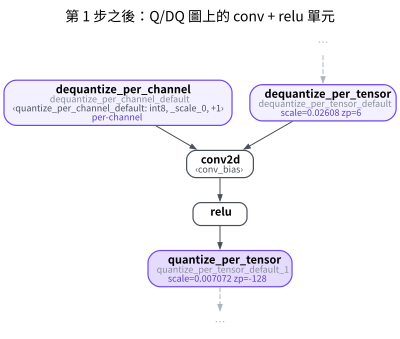

In [3]:
#| echo: false
draw(qdq, focus=["conv2d", "relu"], hops=1, title="第 1 步之後：Q/DQ 圖上的 conv + relu 單元")

這就是 M07 概覽開頭的「dq → op → q」單元：int8 進、int8 出，中間的 conv、relu 用 fp32 算。

**第 2 步：lowering。** 再 export 一次（`to_edge_transform_and_lower` 吃 `ExportedProgram`，`convert_pt2e` 給的是 GraphModule），然後讓 `XnnpackPartitioner` 切出 XNNPACK 吃得下的子圖：

In [4]:
edge = to_edge_transform_and_lower(torch.export.export(qdq, x), partitioner=[XnnpackPartitioner()])
lowered = edge.exported_program().graph_module

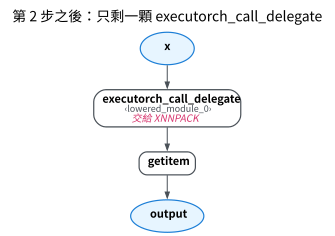

In [5]:
#| echo: false
draw(lowered, notes={"executorch_call_delegate": "交給 XNNPACK"}, title="第 2 步之後：只剩一顆 executorch_call_delegate")

conv、relu、q/dq 全都不見了，換成一顆 `executorch_call_delegate`。它呼叫的 `lowered_module_0` 是 XNNPACK 的 delegate，裡面保留著被收進去的原始子圖：

In [6]:
delegate = getattr(lowered, "lowered_module_0")
inner = delegate.original_module.graph_module                   # 被收進 delegate 的子圖
print("backend：", delegate.backend_id)

backend： XnnpackBackend


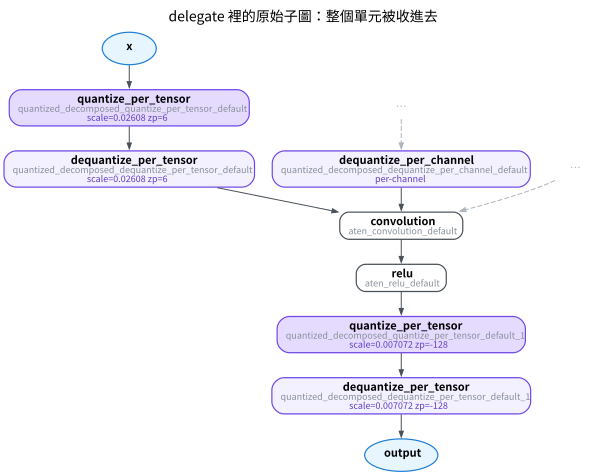

In [7]:
#| echo: false
draw(inner, focus=lambda n: n.op != "placeholder" or n.name == "x", hops=0,
     title="delegate 裡的原始子圖：整個單元被收進去")

整個單元，連同 weight 的 `dequantize_per_channel`，都在 delegate 裡。名稱也變了：`conv2d` 在 Edge dialect 已經 decompose 成 `convolution`。

**第 3 步：序列化成 `.pte`。** `to_executorch()` 為 delegate 以外的圖做 memory planning，`.buffer` 是 `.pte` 檔的 bytes：

In [8]:
pte = edge.to_executorch().buffer
print(f".pte：{len(pte)} bytes")

.pte：3872 bytes


部署時交出去的就是這些 bytes（寫成 `model.pte` 檔）。

**第 4 步：用 ExecuTorch runtime 執行。** 第一次載入 XNNPACK delegate 時，ExecuTorch 的 C++ 層會在 stderr 印幾行偵測 CPU 的 log，和結果無關，用本專案的 `capture_stderr()`（`common/env.py`，不是 executorch 的 API）收起來：

In [9]:
with capture_stderr():
    program = Runtime.get().load_program(pte)                   # 也可以傳 .pte 檔的路徑
    forward = program.load_method("forward")
assert forward is not None
y = forward.execute([x[0]])[0]
print("輸出 shape：", tuple(y.shape))

輸出 shape： (1, 8, 16, 16)


`program` 在執行期間要一直留著：只留 `forward`、讓 `program` 被回收的話，`forward` 執行時會讀到已釋放的記憶體。

後面的 notebook 用本專案的三個包裝（`common/executorch_utils.py`，都不是 executorch 的 API）：

| 包裝 | 做的事 |
|---|---|
| `xnnpack_ptq(model, x)` | 第 1 步：static shape 的 export、executorch 版 quantizer、校準、convert |
| `lower_to_xnnpack(gm, x)` | 第 2、3 步，回傳 `(edge, pte)` |
| `PteRunner(pte)` | 第 4 步，並留住 `program` |

## 名詞

| 名詞 | 是什麼 |
|---|---|
| Edge dialect | ExecuTorch 的中間表示：大多數 op 再 decompose 成 Core ATen op（例如 `conv2d` → `convolution`）；partitioner 可以要求保留它認得的 op 不拆（例如 `linear`，讀 executorch 1.5.0 的 `config_partitioner.py`） |
| partitioner | 在圖上找出某個 backend 吃得下的連通子圖；這裡是 `XnnpackPartitioner` |
| delegate | 交給 backend 的一塊子圖，backend 在匯出時把它編譯成自己的格式；圖上留下一顆 `executorch_call_delegate` |
| memory planning | `to_executorch()` 依匯出時的 shape，事先決定每個中間 tensor 放在哪塊記憶體，執行時不再配置 |
| `.pte` | ExecuTorch 的部署檔：圖、weight、delegate 的資料、memory plan 都在裡面 |
| portable kernel | ExecuTorch 自己的通用 C++ op 實作，跑沒有進 delegate 的 op |

## lowering 時 q/dq 去哪了

Q/DQ 圖上的 q/dq 都進了 delegate，但不是每一顆都變成運算。XNNPACK 把它們分成兩種（讀 executorch 1.5.0 的 `backends/xnnpack/operators/op_quant_dequant.py`、`quant_params.py`）：

| Q/DQ 圖上 | 到了 XNNPACK |
|---|---|
| 夾在兩個 op 之間的 q、dq | 不產生運算，只把 scale、zero point 記在 int8 tensor 上（`QuantParams.from_q_dq_node`）。一個單元就是一顆 int8 kernel（M08-2 A 印出 delegate 裡的 node） |
| 圖入口的 q、出口的 dq | 變成 fp32 ↔ int8 的轉換（XNNPACK 的 `Convert`） |
| weight（int8 常數 + per-channel scale） | 原樣存進 `.pte` |
| fp32 bias | 量化成 int32，scale = $s_x \cdot s_w$（`QuantParams.from_bias`） |
| partitioner 不收的 op | 留在 delegate 外，由 portable kernel 執行（M08-3） |

所以 XNNPACK 用的 scale，就是 `convert_pt2e` 寫在 q/dq 上的那一套（observer 的 `calculate_qparams()`）。QAT 的模型也一樣：部署用的是 convert 圖上的 scale，不是訓練時 fake quant 的 buffer（M06-3）。

## 和 Q/DQ 圖的數值差異

兩邊拿到相同的 scale、zero point，輸出仍不保證逐位元相同：Q/DQ 圖用 fp32 模擬量化，XNNPACK 用整數 kernel 算，捨入的位置不同。

- 已知的一個原因是 bias：Q/DQ 圖上 bias 是 fp32，XNNPACK 在 lowering 時把它量化成 int32（上表）。
- 其他可能的來源是 add、mean 的整數實作，以及 conv 的累加方式（推論，沒有讀 XNNPACK 的 kernel 原始碼）。

這些差來自整數捨入：在 executorch 1.5.0、macOS arm64 上，M08-2、M08-3 量到的最大差都是 1 個輸出 LSB。所以在 Q/DQ 圖上評估精度（M05、M06）可以代表部署的結果，只是別期待逐位元相同。比較的指標照 M07 概覽〈比較後端之前的規矩〉。

## 小結與本章地圖

- 路線 A 在匯出時就決定 kernel：`to_edge_transform_and_lower` 讓 partitioner 切出 delegate，`.pte` 裡存的就是 XNNPACK 要執行的子圖。
- 夾在 op 之間的 q/dq 只剩 int8 tensor 的 scale；只有圖的入口、出口真的轉換 fp32 ↔ int8。
- `.pte` 依匯出時的 shape 做 memory planning，所以這一章一律用 static shape。

| notebook | 回答的問題 |
|---|---|
| [M08-1 兩份 XNNPACKQuantizer](01_executorch_vs_torchao_copy.ipynb) | executorch 版與 torchao 測試版差在哪；static 與 dynamic 的規格；`set_module_name` |
| [M08-2 從 Q/DQ 圖到 `.pte`](02_export_to_pte.ipynb) | lowering 前後的圖、delegate 裡的 XNNPACK node、`.pte` 的大小、runtime 執行、換 batch 會怎樣 |
| [M08-3 不支援的 op](03_unsupported_ops.ipynb) | 圖怎麼被切開、邊界上傳什麼、和 Q/DQ 圖差多少 |
| [M08-4 latency](04_latency.ipynb) | eager、Q/DQ 圖、fp32 `.pte`、int8 `.pte` 誰快；收益分兩段 |

這一章刻意跳過的：動態 shape 的 `.pte`；XNNPACK 以外的 ExecuTorch backend（M07 概覽列出的那些）；ONNX Runtime 的路線 B 在 M09。

## 參考資料

- ExecuTorch 文件：[Backends 總覽](https://docs.pytorch.org/executorch/stable/backends-overview.html)、[XNNPACK backend](https://docs.pytorch.org/executorch/stable/backends-xnnpack.html)
- executorch 1.5.0 原始碼：[`backends/xnnpack/operators/op_quant_dequant.py`](https://github.com/pytorch/executorch/blob/v1.5.0/backends/xnnpack/operators/op_quant_dequant.py)、[`quant_params.py`](https://github.com/pytorch/executorch/blob/v1.5.0/backends/xnnpack/operators/quant_params.py)、[`backends/xnnpack/quantizer/xnnpack_quantizer.py`](https://github.com/pytorch/executorch/blob/v1.5.0/backends/xnnpack/quantizer/xnnpack_quantizer.py)
- [XNNPACK](https://github.com/google/XNNPACK)